# 02 — Modélisation, sélection et évaluation

**Protocole**
1. Hold-out stratifié : 80 % entraînement (712 passagers), 20 % test (179), consulté **une seule fois**.
2. Deux baselines : classe majoritaire et règle « les femmes survivent ».
3. Trois modèles (régression logistique, Random Forest, Gradient Boosting), hyperparamètres optimisés par **validation croisée stratifiée répétée 5 × 5** sur le train.
4. Sélection du modèle sur la moyenne de validation croisée, puis évaluation finale sur le test avec intervalle de confiance bootstrap.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
FIG = ROOT / "reports" / "figures"

In [2]:
from titanic.train import run, PRETTY

report = run()          # ≈ 1 minute : 3 grilles × 25 plis ; écrit models/ et reports/figures/
rows = []
for name in ["baseline_majority", "baseline_gender", "logistic_regression", "random_forest", "gradient_boosting"]:
    rows.append({"Modèle": PRETTY[name],
                 "CV accuracy": f"{report['cv'][name]['mean']:.3f} ± {report['cv'][name]['std']:.3f}",
                 **{f"Test {k}": round(v, 3) for k, v in report["test"][name].items()}})
pd.DataFrame(rows).set_index("Modèle")

,CV accuracy,Test accuracy,Test precision,Test recall,Test f1,Test roc_auc,Test brier
Modèle,,,,,,,
Baseline : classe majoritaire,0.617 ± 0.003,0.615,0.000,0.000,0.000,0.500,0.385
Baseline : « les femmes survivent »,0.789 ± 0.032,0.777,0.738,0.652,0.692,0.753,0.223
Régression logistique,0.826 ± 0.042,0.849,0.818,0.783,0.800,0.867,0.132
Random Forest,0.834 ± 0.034,0.810,0.807,0.667,0.730,0.846,0.140
Gradient Boosting,0.833 ± 0.030,0.804,0.804,0.652,0.720,0.832,0.150


In [3]:
print("Modèle retenu :", PRETTY[report["model"]], report["best_params"][report["model"]])
lo, hi = report["test_accuracy_ci95"]
print(f"Accuracy test : {report['test'][report['model']]['accuracy']:.3f}  (IC 95 % : [{lo:.3f} ; {hi:.3f}])")

Modèle retenu : Random Forest {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 300}
Accuracy test : 0.810  (IC 95 % : [0.749 ; 0.866])


## Comparaison en validation croisée

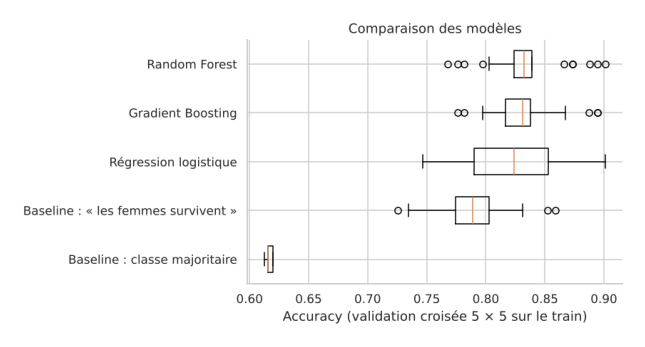

In [4]:
img = plt.imread(FIG / "cv_comparison.png"); plt.figure(figsize=(9, 4.8)); plt.imshow(img); _ = plt.axis("off")

Les trois modèles dépassent nettement les deux baselines (+3,7 à +4,5 points d'accuracy par rapport à la règle « les femmes survivent »). En revanche, **leurs écarts entre eux (< 1 point) sont bien plus petits que la variabilité d'un pli à l'autre (≈ ± 4 points)** : on ne peut pas affirmer qu'un modèle est meilleur que les autres.

## Courbes ROC et matrice de confusion (test)

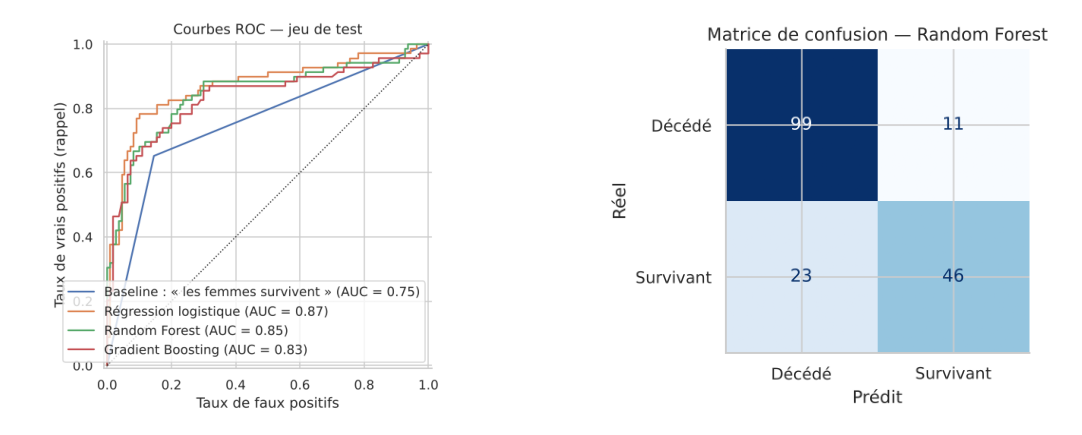

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, f in zip(axes, ["roc_curves.png", "confusion_matrix.png"]):
    ax.imshow(plt.imread(FIG / f)); ax.axis("off")
plt.tight_layout()

## Le test contredit-il la validation croisée ?

In [6]:
import joblib
from scipy.stats import binomtest
from sklearn.base import clone

from titanic.config import load_params
from titanic.data import load_data, split_data
from titanic.models import build_candidates

params = load_params()
X_train, X_test, y_train, y_test = split_data(load_data(params), params)

lr = clone(build_candidates(params["seed"])["logistic_regression"]).set_params(
    classifier__C=report["best_params"]["logistic_regression"]["C"]).fit(X_train, y_train)
rf = joblib.load(ROOT / "models" / "model.joblib")

lr_ok = lr.predict(X_test) == y_test
rf_ok = rf.predict(X_test) == y_test
b, c = int((lr_ok & ~rf_ok).sum()), int((~lr_ok & rf_ok).sum())
print(f"Bien classés par la régression logistique seulement : {b}")
print(f"Bien classés par la Random Forest seulement : {c}")
print(f"Test de McNemar exact : p = {binomtest(b, b + c, 0.5).pvalue:.3f}")

Bien classés par la régression logistique seulement : 12
Bien classés par la Random Forest seulement : 5
Test de McNemar exact : p = 0.143


Sur le test, la régression logistique obtient une meilleure accuracy que la Random Forest retenue. Mais le test de McNemar (qui ne compare que les passagers sur lesquels les deux modèles divergent) ne montre **pas de différence significative**. Avec 179 passagers, l'intervalle de confiance de l'accuracy s'étend sur environ ± 6 points.

**Nous ne changeons pas de modèle après avoir vu le test** : le faire transformerait le test en jeu de sélection et rendrait le score annoncé optimiste. Ce point de méthode est volontairement documenté.

## Interprétation : coefficients de la régression logistique

Title_Master    2.52
Sex_female      2.35
Title_Mrs       2.16
Deck_E          2.09
Deck_D          1.95
IsChild         1.71
LogFare         1.54
HasCabin        1.54
Name: odds ratio, dtype: float64

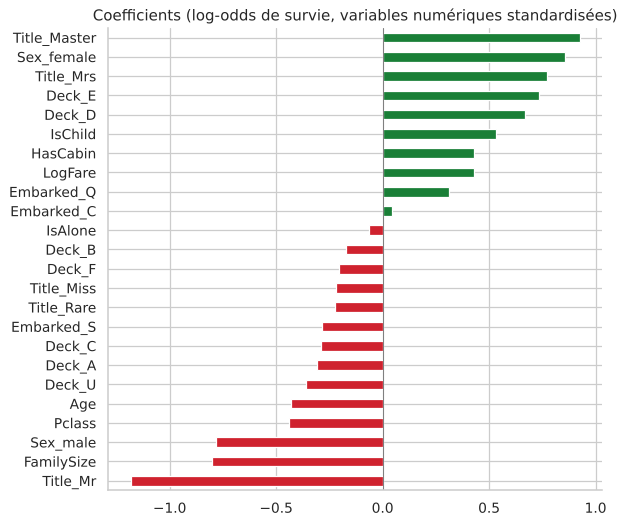

In [7]:
names = lr.named_steps["prep"].named_steps["columns"].get_feature_names_out()
coef = pd.Series(lr.named_steps["classifier"].coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
coef.plot.barh(ax=ax, color=["#cf222e" if v < 0 else "#1a7f37" for v in coef])
ax.axvline(0, color="grey", lw=0.8)
ax.set_title("Coefficients (log-odds de survie, variables numériques standardisées)")
plt.tight_layout()
(np.exp(coef).round(2)).rename("odds ratio").sort_values(ascending=False).head(8)

## Importance par permutation (modèle retenu)

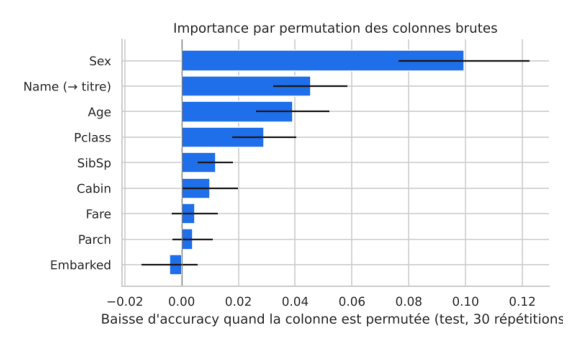

In [8]:
plt.figure(figsize=(8, 4.8)); plt.imshow(plt.imread(FIG / "permutation_importance.png")); _ = plt.axis("off")

Le sexe est de loin la variable la plus utile au modèle, suivie du nom (via le titre), de l'âge et de la classe. Le port d'embarquement n'apporte rien une fois les autres variables connues, ce qui confirme l'effet de confusion observé dans l'EDA.

## Analyse des erreurs

In [9]:
errors = X_test.assign(Survived=y_test, proba=rf.predict_proba(X_test)[:, 1])
errors = errors[(errors["proba"] >= 0.5) != errors["Survived"].astype(bool)]
errors["type"] = np.where(errors["Survived"] == 1, "survivant prédit décédé", "décédé prédit survivant")
print(errors["type"].value_counts().to_string())
errors.groupby(["type", "Sex", "Pclass"]).size().rename("n").reset_index()

type
survivant prédit décédé    23
décédé prédit survivant    11


,type,Sex,Pclass,n
0,décédé prédit survivant,female,1,1
1,décédé prédit survivant,female,2,1
2,décédé prédit survivant,female,3,4
3,décédé prédit survivant,male,1,4
4,décédé prédit survivant,male,3,1
5,survivant prédit décédé,female,3,6
6,survivant prédit décédé,male,1,9
7,survivant prédit décédé,male,2,2
8,survivant prédit décédé,male,3,6


Les erreurs se concentrent sur les profils « à contre-courant » de la règle dominante : la moitié des erreurs (17 sur 34) sont des **hommes ayant survécu** que le modèle prédisait décédés, et 10 concernent des **femmes de 3e classe**, dont le sort était proche d'un tirage à pile ou face (50 % de survie). Ce sont précisément les cas que les variables disponibles ne permettent pas d'expliquer (emplacement au moment du naufrage, accès aux canots…) : une limite des données plus que du modèle.